# Regresión: Comparación de Modelos

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from ModeladoRegresion import (
    SEED, USAR_GPU, CORTE_BDI, TARGET_CLF, NOMBRES_REG, NOMBRES_FASE2_REG, CLAVE_BENCHMARK, VARIANTES,
    cargar_split, separar_x_y_reg, crear_cv_reg, resumen_target, resumen_dispositivos_reg,
    cargar_ganador_reg, crear_benchmark_reg, evaluar_cv_reg, formatear_tabla_cv_reg, elegir_modelo_reg,
    formatear_hiperparametros, evaluar_test_reg, graficar_intervalos_bootstrap_reg,
    graficar_predicho_vs_real, graficar_residuos_vs_predicho,
    importancia_permutacion, cargar_clasificador_final, comparar_jerarquias, graficar_importancias,
    metricas_riesgo, graficar_matrices, graficar_roc_pr_riesgo, comparar_auc_bootstrap,
    guardar_final_reg, cargar_modelo_regresion,
)

In [2]:
resumen_dispositivos_reg().style.set_caption(f"USAR_GPU = {USAR_GPU}")

,Dispositivo,n_jobs búsqueda
Modelo,,
Lineal (OLS),CPU,-1
Ridge,CPU,-1
Lasso,CPU,-1
ElasticNet,CPU,-1
GLM Poisson,CPU,-1
GLM binomial negativa,CPU,-1
KNN,CPU,-1
SVR (RBF),CPU,-1
Random Forest,CPU,-1


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, df_test = cargar_split(df)
X_train, y_train = separar_x_y_reg(df_train)
X_test, y_test = separar_x_y_reg(df_test)
y_dep_test = df_test[TARGET_CLF]
cv = crear_cv_reg(SEED)

pd.concat([resumen_target(y_train), resumen_target(y_test).rename(index={"Train": "Test"})])

,Filas,Media,Mediana,DE,Asimetría,Ceros (%),BDI ≥ 14 (%)
Conjunto,,,,,,,
Train,3848,7.30,5.0,7.75,1.90,10.5,16.4
Test,962,7.15,5.0,7.53,1.83,10.9,16.3


Train y test tienen distribuciones del BDI muy parecidas (media de 7.30 y 7.15, la misma mediana, y un 16.4% y un 16.3% con BDI ≥ 14). El split, que se estratificó por sexo × depresión, también es representativo para la regresión.

## Comparación de Modelos

Se carga el Pipeline ganador de cada modelo (ya reentrenado con todo el train) y su `ganador.json`. Se agrega la **regresión lineal benchmark del EDA** (`LinearRegression`, target nativo, sin tuning) como **modelo de referencia fijo**. Se entrena aquí con el train porque no tiene hiperparámetros.

Sus métricas **no coinciden exactamente con las del EDA** (R² = 0.221): allí se usaron 5 predictores (sin `social_jetlag_hours`) y una CV de 5 folds sobre todo el dataset, mientras que aquí usa los 6 predictores del modelado y solo el train del split compartido con la clasificación. Además, como sus predicciones también se recortan a [0, 63], es el mismo modelo que la variante nativa de `reg_lineal`.

In [4]:
pipelines, ganadores = {}, {}
for clave in NOMBRES_REG:
    pipelines[clave], ganadores[clave] = cargar_ganador_reg(clave)

# Modelo de referencia fijo
pipelines = {CLAVE_BENCHMARK: crear_benchmark_reg().fit(X_train, y_train), **pipelines}

pd.DataFrame({
    "Variante": [VARIANTES[g["variante"]] for g in ganadores.values()],
    "RMSE fase 1": [f"{g['rmse_media']:.3f} ± {g['rmse_de']:.3f}" for g in ganadores.values()],
    "Hiperparámetros": [formatear_hiperparametros(g["hiperparametros"]) for g in ganadores.values()],
    "Dispositivo": [g["dispositivo_entrenamiento"] for g in ganadores.values()],
}, index=pd.Index([NOMBRES_REG[c] for c in ganadores], name="Modelo"))

,Variante,RMSE fase 1,Hiperparámetros,Dispositivo
Modelo,,,,
Lineal (OLS),Nativo,6.900 ± 0.485,sin tuning,CPU
Ridge,Nativo,6.900 ± 0.486,alpha=24.66,CPU
Lasso,Nativo,6.900 ± 0.486,alpha=0.007459,CPU
ElasticNet,Nativo,6.900 ± 0.487,"alpha=0.01445, l1_ratio=0.333",CPU
GLM Poisson,Nativo,7.003 ± 0.454,alpha=0.4571,CPU
GLM binomial negativa,Nativo,7.164 ± 0.409,sin tuning,CPU
KNN,Nativo,6.958 ± 0.536,"n_neighbors=102, p=1, weights=distance",CPU
SVR (RBF),Nativo,7.065 ± 0.539,"C=65.84, epsilon=2.601, gamma=0.06219",CPU
Random Forest,Nativo,6.894 ± 0.498,"max_depth=None, max_features=0.5, min_samples_leaf=50, n_estimators=291",CPU


Los 12 modelos eligieron la variante nativa en la fase 1, seis de ellos (KNN, SVR y los cuatro modelos de árboles) por la regla de empate. Por eso ningún modelo de la comparación usa smearing.

### Validación Cruzada

Todos los modelos, con los hiperparámetros elegidos en la fase 1 (sin volver a ajustarlos), se evalúan con `cross_validate` en los mismos folds. La tabla muestra media ± desviación de RMSE, MAE y R² en puntos BDI, ordenada por RMSE, y la diferencia frente al benchmark (Δ RMSE y Δ MAE negativos y Δ R² positivo indican mejora).

In [5]:
tabla_cv = evaluar_cv_reg(pipelines, X_train, y_train, cv)
formatear_tabla_cv_reg(tabla_cv).rename(index=NOMBRES_FASE2_REG)

✓ Lineal benchmark (EDA)   RMSE = 6.9004 ± 0.4850
✓ Lineal (OLS)             RMSE = 6.9004 ± 0.4850
✓ Ridge                    RMSE = 6.9000 ± 0.4862
✓ Lasso                    RMSE = 6.8998 ± 0.4858
✓ ElasticNet               RMSE = 6.8997 ± 0.4870
✓ GLM Poisson              RMSE = 7.0027 ± 0.4541
✓ GLM binomial negativa    RMSE = 7.1636 ± 0.4087
✓ KNN                      RMSE = 6.9578 ± 0.5355
✓ SVR (RBF)                RMSE = 7.0649 ± 0.5386
✓ Random Forest            RMSE = 6.8943 ± 0.4978
✓ XGBoost                  RMSE = 6.8876 ± 0.4884
✓ LightGBM                 RMSE = 6.9020 ± 0.4824
✓ CatBoost                 RMSE = 6.8815 ± 0.4803


,RMSE,MAE,R²,Δ RMSE vs benchmark,Δ MAE vs benchmark,Δ R² vs benchmark
Modelo,,,,,,
CatBoost,6.881 ± 0.480,4.884 ± 0.186,0.205 ± 0.017,-0.019,-0.023,0.004
XGBoost,6.888 ± 0.488,4.904 ± 0.182,0.204 ± 0.015,-0.013,-0.002,0.003
Random Forest,6.894 ± 0.498,4.914 ± 0.189,0.203 ± 0.014,-0.006,0.008,0.002
ElasticNet,6.900 ± 0.487,4.907 ± 0.188,0.201 ± 0.016,-0.001,0.001,0.000
Lasso,6.900 ± 0.486,4.906 ± 0.188,0.201 ± 0.016,-0.001,-0.000,0.000
Ridge,6.900 ± 0.486,4.907 ± 0.188,0.201 ± 0.016,-0.000,0.000,0.000
Lineal benchmark (EDA),6.900 ± 0.485,4.906 ± 0.187,0.201 ± 0.016,0.000,0.000,0.000
Lineal (OLS),6.900 ± 0.485,4.906 ± 0.187,0.201 ± 0.016,0.000,0.000,0.000
LightGBM,6.902 ± 0.482,4.909 ± 0.182,0.200 ± 0.017,0.002,0.003,-0.000


Los nueve mejores modelos quedan en un rango de solo 0.021 puntos de RMSE (de 6.881 a 6.902) y de 0.005 de R² (de 0.200 a 0.205). CatBoost obtiene el menor RMSE (6.881 ± 0.480), seguido de XGBoost (6.888) y Random Forest (6.894), pero su mejora frente al benchmark es de solo 0.019 puntos de RMSE y 0.004 de R². Los cuatro modelos lineales son prácticamente idénticos al benchmark: la variante nativa de OLS es el mismo modelo, y las penalizaciones elegidas son mínimas.

Por detrás quedan KNN (6.958), el GLM Poisson (7.003), el SVR (7.065) y la binomial negativa (7.164), todos peores que el benchmark. El SVR tiene el menor MAE (4.727) por su pérdida ε-insensible, que lleva la predicción hacia la mediana en vez de hacia la media.

La desviación del RMSE entre folds (≈ 0.48) es unas 25 veces mayor que la diferencia entre CatBoost y el benchmark. Esa desviación refleja sobre todo que los folds difieren en la dispersión del BDI; la del R², que se normaliza por esa dispersión, es de solo ≈ 0.016.

### Selección del Mejor Modelo

Entre los 12 ganadores se elige el de **menor RMSE medio de CV**, con la misma **regla de empate** de la fase 1: si un modelo más simple queda a menos de una desviación estándar de CV del ganador, se elige el más simple. Orden de simplicidad: lineales (OLS, Ridge, Lasso, ElasticNet) < Poisson < binomial negativa < KNN < SVR < Random Forest < boosting (XGBoost, LightGBM, CatBoost).

El benchmark no compite: es la referencia contra la que se mide la ganancia.

In [6]:
clave_mejor, explicacion = elegir_modelo_reg(tabla_cv.drop(index=CLAVE_BENCHMARK))

pd.Series({
    "Modelo elegido": NOMBRES_REG[clave_mejor],
    "Variante del target": VARIANTES[ganadores[clave_mejor]["variante"]],
    "RMSE de CV": f"{tabla_cv.loc[clave_mejor, 'RMSE media']:.4f} ± {tabla_cv.loc[clave_mejor, 'RMSE DE']:.4f}",
    "Δ RMSE de CV vs benchmark": f"{tabla_cv.loc[clave_mejor, 'Δ RMSE vs benchmark']:+.4f}",
    "Criterio": explicacion,
}, name="Selección").to_frame()

,Selección
Modelo elegido,ElasticNet
Variante del target,Nativo
RMSE de CV,6.8997 ± 0.4870
Δ RMSE de CV vs benchmark,-0.0007
Criterio,"El menor RMSE medio de CV es el de 'CatBoost' (6.8815 ± 0.4803), pero 'ElasticNet' es más simple y su RMSE (6.8997) está a solo 0.0182 puntos, menos que la desviación estándar de CV de la ganadora (0.4803). Por la regla de empate se elige 'ElasticNet'."


CatBoost tiene el menor RMSE medio (6.8815), pero ElasticNet, del grupo más simple, está a solo 0.018 puntos, muy por debajo de la desviación entre folds de CatBoost (0.480). Por la regla de empate se elige ElasticNet. Los cuatro modelos lineales quedan a menos de una desviación de CatBoost, y ElasticNet es el de menor RMSE entre ellos (6.8997), aunque su ventaja sobre OLS es de 0.0007 puntos. En la práctica, el modelo elegido es una regresión lineal casi sin penalizar.

## Test

Los 13 modelos (12 ganadores + benchmark), ya entrenados con todo el train, se evalúan **una única vez** en el test. El test no se usó para el tuning, ni para elegir variantes o modelo, ni para el smearing.

**Intervalos bootstrap al 95%:** se generan 1000 réplicas del test remuestreando adolescentes con reemplazo, y en cada una se evalúan **todos los modelos sobre las mismas observaciones**. Además del intervalo del RMSE y del R² de cada modelo, se obtiene el de la **diferencia pareada frente al benchmark**: si no incluye el 0, la diferencia es real con un 95% de confianza (columna `significativa`).

In [7]:
predicciones_test = {clave: pipeline.predict(X_test) for clave, pipeline in pipelines.items()}

tabla_test = evaluar_test_reg(y_test, predicciones_test, n_replicas=1000, seed=SEED)
columnas = ["RMSE", "RMSE IC 2.5%", "RMSE IC 97.5%", "MAE", "R²", "R² IC 2.5%", "R² IC 97.5%"]
tabla_test[columnas].rename(index=NOMBRES_FASE2_REG).round(3)

,RMSE,RMSE IC 2.5%,RMSE IC 97.5%,MAE,R²,R² IC 2.5%,R² IC 97.5%
Modelo,,,,,,,
Lasso,6.594,6.075,7.138,4.725,0.233,0.174,0.285
ElasticNet,6.595,6.075,7.139,4.726,0.232,0.174,0.285
Lineal (OLS),6.595,6.077,7.139,4.725,0.232,0.173,0.284
Lineal benchmark (EDA),6.595,6.077,7.139,4.725,0.232,0.173,0.284
Ridge,6.596,6.076,7.140,4.726,0.232,0.174,0.285
XGBoost,6.602,6.081,7.145,4.731,0.231,0.178,0.278
CatBoost,6.620,6.101,7.154,4.726,0.227,0.169,0.277
Random Forest,6.630,6.102,7.178,4.735,0.224,0.172,0.271
LightGBM,6.642,6.125,7.183,4.731,0.221,0.164,0.274


En el test, los modelos lineales quedan en cabeza: Lasso, ElasticNet, OLS, el benchmark y Ridge obtienen un RMSE de 6.594 a 6.596 y un R² de 0.232. Los árboles, que ganaban en CV, quedan justo detrás (XGBoost 6.602, CatBoost 6.620, Random Forest 6.630 y LightGBM 6.642), y al final vuelven a estar el GLM Poisson (6.697), el SVR (6.704) y la binomial negativa (6.868). El orden cambia respecto a la CV, pero las diferencias entre los nueve primeros son menores de 0.05 puntos.

El R² en test (0.232) es mayor que el de CV (0.201) y algo mayor que el del EDA (0.221). Es variabilidad de muestreo y no una mejora del modelo: el test, con 962 adolescentes, resulta algo más fácil de predecir (RMSE de 6.595 frente a 6.900 en CV), y el intervalo bootstrap del R² del benchmark es amplio (0.173 a 0.284).

In [8]:
columnas_delta = [c for c in tabla_test.columns if c.startswith("Δ")]
tabla_test[columnas_delta].rename(index=NOMBRES_FASE2_REG).round(3)

,Δ RMSE vs benchmark,Δ RMSE IC 2.5%,Δ RMSE IC 97.5%,Δ RMSE significativa,Δ R² vs benchmark,Δ R² IC 2.5%,Δ R² IC 97.5%,Δ R² significativa
Modelo,,,,,,,,
Lasso,-0.001,-0.003,0.001,False,0.000,-0.000,0.001,False
ElasticNet,-0.000,-0.005,0.005,False,0.000,-0.001,0.001,False
Lineal (OLS),0.000,0.000,0.000,False,0.000,0.000,0.000,False
Lineal benchmark (EDA),0.000,0.000,0.000,False,0.000,0.000,0.000,False
Ridge,0.000,-0.003,0.003,False,-0.000,-0.001,0.001,False
XGBoost,0.006,-0.064,0.070,False,-0.001,-0.016,0.016,False
CatBoost,0.024,-0.076,0.126,False,-0.006,-0.029,0.018,False
Random Forest,0.035,-0.048,0.115,False,-0.008,-0.026,0.012,False
LightGBM,0.046,-0.041,0.130,False,-0.011,-0.030,0.009,False


Ningún modelo mejora significativamente al benchmark: todos los intervalos de Δ RMSE y Δ R² incluyen el 0, salvo dos que son significativamente **peores**. Son el GLM Poisson (Δ RMSE = +0.102, IC: 0.007 a 0.201) y la binomial negativa (Δ RMSE = +0.272, IC: 0.080 a 0.504).

Los intervalos de los modelos lineales son muy estrechos (± 0.005) porque sus predicciones son casi idénticas a las del benchmark. Los de los árboles son más anchos (≈ ± 0.07 a 0.13) porque sus predicciones difieren más de una observación a otra.

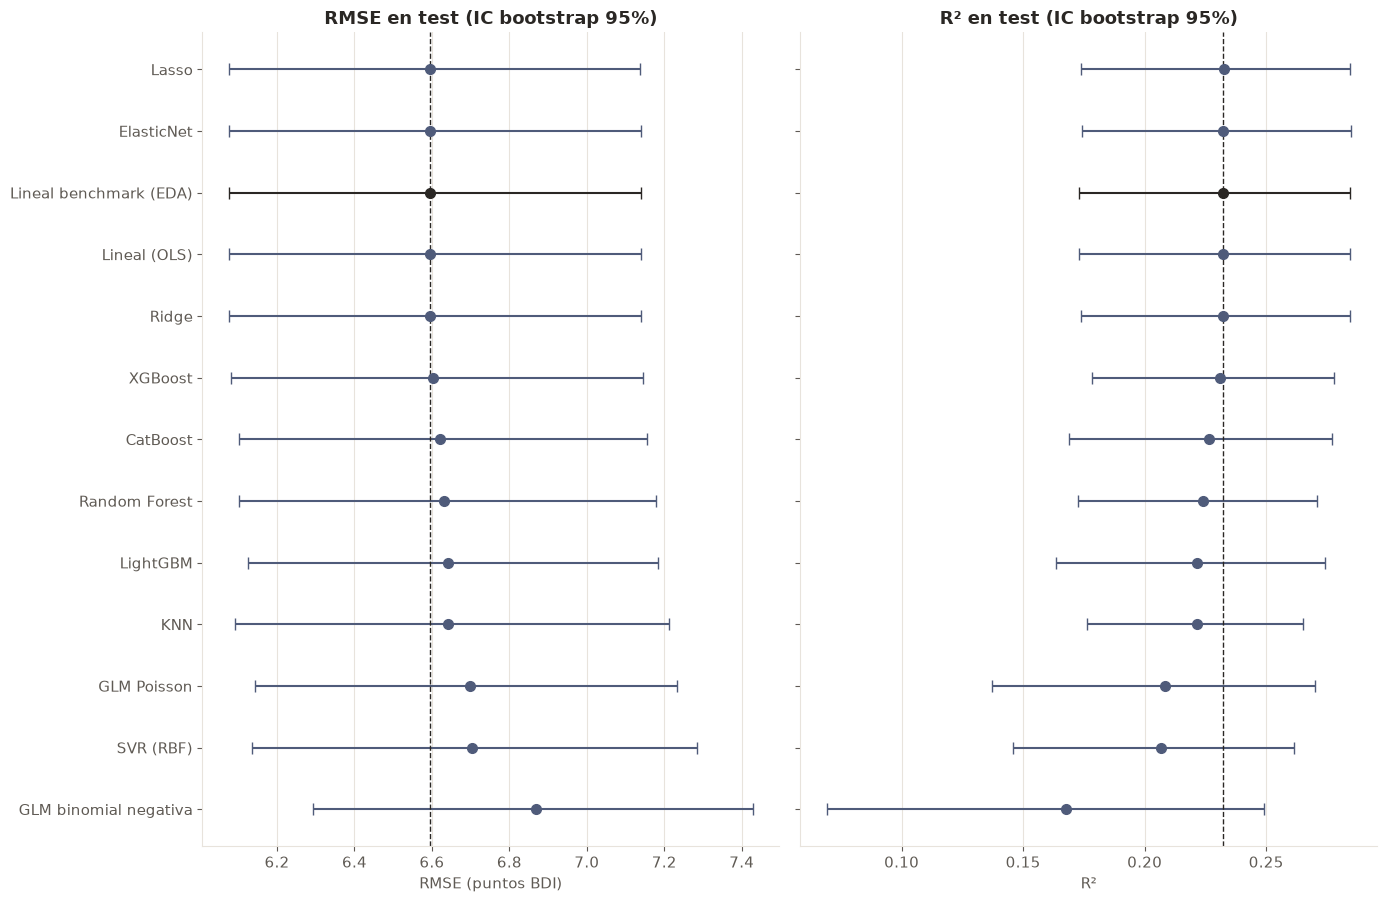

In [9]:
fig = graficar_intervalos_bootstrap_reg(tabla_test)
plt.show()

La gráfica resume lo mismo: los intervalos del RMSE (≈ 6.1 a 7.2) y del R² (≈ 0.17 a 0.28) de casi todos los modelos se solapan casi por completo con los del benchmark (línea discontinua). Solo la binomial negativa se separa con claridad hacia peor.

**Predicho vs. real**

Benchmark y modelo elegido en el test, con la diagonal (predicción perfecta) y el corte clínico (BDI = 14) en ambos ejes.

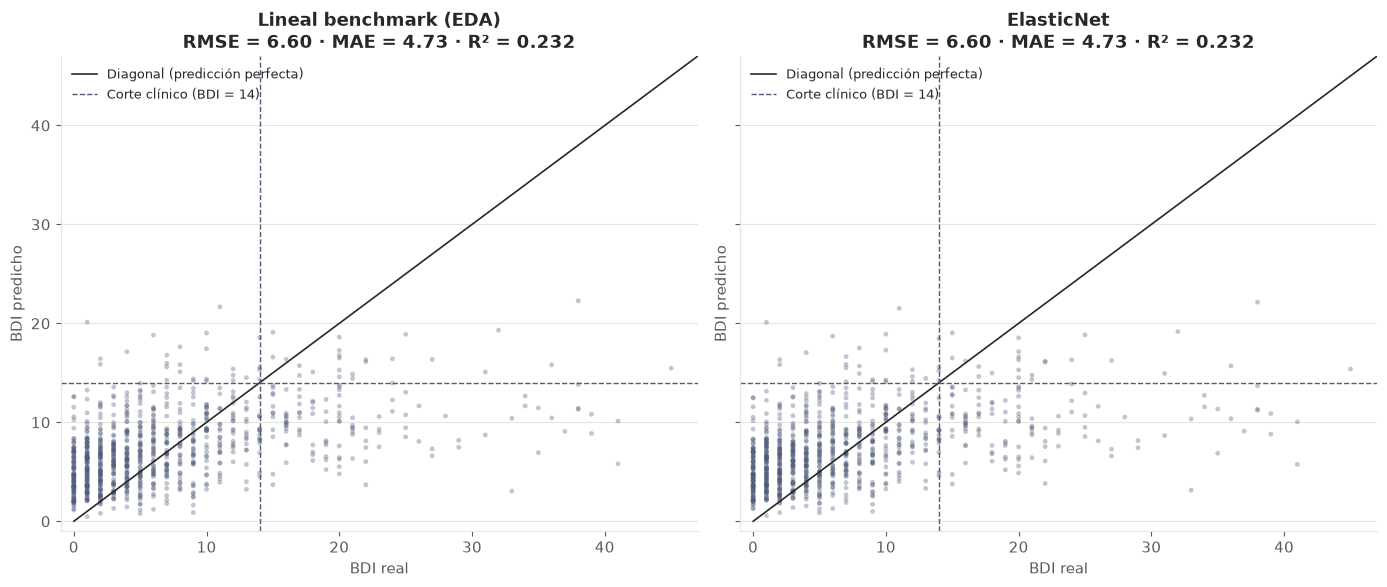

In [10]:
fig = graficar_predicho_vs_real(y_test, {
    NOMBRES_FASE2_REG[CLAVE_BENCHMARK]: predicciones_test[CLAVE_BENCHMARK],
    NOMBRES_REG[clave_mejor]: predicciones_test[clave_mejor],
})
plt.show()

Los dos paneles son prácticamente idénticos, porque ElasticNet es casi el mismo modelo que el benchmark (mismo RMSE, MAE y R²). Ambos muestran el patrón típico de un R² modesto, la **regresión a la media**. Las predicciones quedan comprimidas entre ≈ 1 y 22 puntos, mientras que el BDI real llega hasta 45. Los adolescentes con un BDI bajo se sobreestiman (a la izquierda, la nube queda por encima de la diagonal) y los de BDI alto se subestiman mucho: casi todos los que tienen un BDI real ≥ 20 reciben predicciones de 5 a 15. Muy pocas predicciones superan el corte de 14, lo que anticipa el problema del experimento con el corte clínico.

## Permutation Importance

Para el mejor regresor, en el test: se desordena cada predictor 30 veces y se mide cuánto **aumenta el RMSE** (scoring `neg_root_mean_squared_error`). Si existe el clasificador final (`data/processed/modelado/final/`), se calcula lo mismo para él (con PR-AUC, en el mismo test) y se comparan las jerarquías de variables.

In [12]:
importancia_reg = importancia_permutacion(pipelines[clave_mejor], X_test, y_test, n_repeats=30, seed=SEED)
importancia_reg.round(4)

,Importancia media,DE,Ranking
Variable,,,
sleep_quality_index,0.7435,0.0869,1
sex,0.3761,0.0574,2
avg_sleep_hours,0.0911,0.0270,3
screen_time_index,0.0381,0.0137,4
midsleep_weekend_hours,0.0200,0.0135,5
social_jetlag_hours,0.0000,0.0000,6


La calidad del sueño es, con diferencia, el predictor más importante: desordenarla aumenta el RMSE en 0.74 puntos. Le siguen el sexo (0.38) y, a gran distancia, la duración del sueño (0.09), el tiempo de pantalla (0.04) y el punto medio del sueño del fin de semana (0.02). Desordenar `social_jetlag_hours` no cambia el RMSE en absoluto (0.0000 ± 0.0000), porque la penalización L1 de ElasticNet anuló su coeficiente.

,Ranking regresión,Ranking clasificación,Importancia regresión (Δ RMSE),Importancia clasificación (Δ PR-AUC),Mismo puesto
Variable,,,,,
sleep_quality_index,1,1,0.7435,0.1611,True
sex,2,2,0.3761,0.0530,True
avg_sleep_hours,3,5,0.0911,0.0050,False
screen_time_index,4,6,0.0381,-0.0071,False
midsleep_weekend_hours,5,4,0.0200,0.0070,False
social_jetlag_hours,6,3,0.0000,0.0169,False


Correlación de Spearman entre los rankings: 0.486


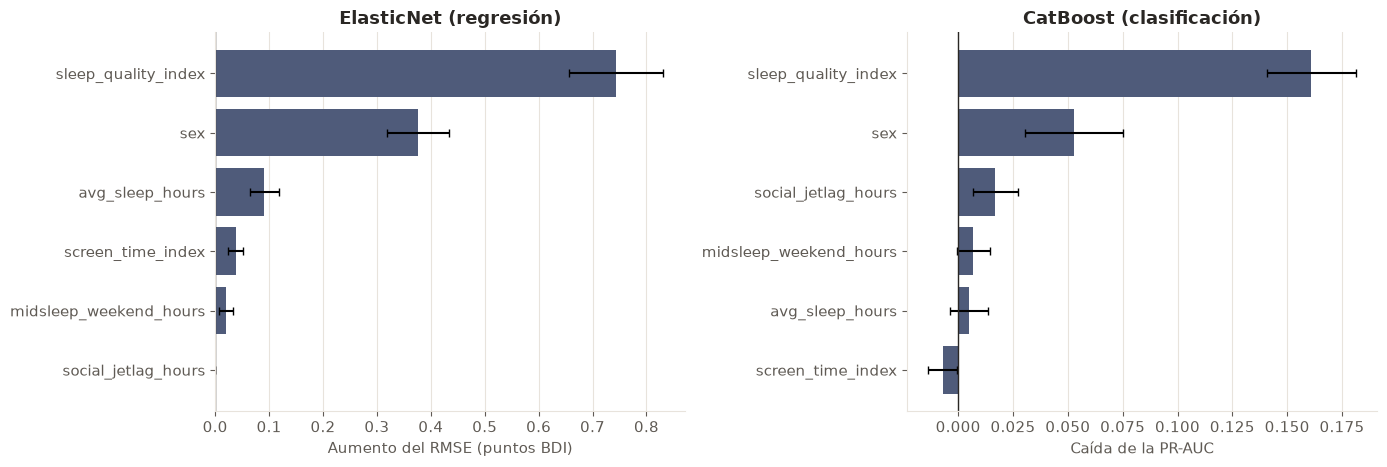

In [13]:
clasificador, metadatos_clf = cargar_clasificador_final()

titulo_reg = f"{NOMBRES_REG[clave_mejor]} (regresión)"
importancias, unidades = {titulo_reg: importancia_reg}, {titulo_reg: "Aumento del RMSE (puntos BDI)"}
if clasificador is not None:
    importancia_clf = importancia_permutacion(
        clasificador, X_test, y_dep_test, scoring="average_precision", n_repeats=30, seed=SEED,
    )
    titulo_clf = f"{metadatos_clf['nombre']} (clasificación)"
    importancias[titulo_clf], unidades[titulo_clf] = importancia_clf, "Caída de la PR-AUC"

    jerarquias, rho = comparar_jerarquias(importancia_reg, importancia_clf)
    display(jerarquias.round(4))
    print(f"Correlación de Spearman entre los rankings: {rho:.3f}")

fig = graficar_importancias(importancias, unidades)
plt.show()

Las dos primeras posiciones coinciden: la calidad del sueño y el sexo dominan tanto la regresión como el clasificador final (CatBoost). Las demás variables tienen importancias pequeñas y su orden difiere, por lo que la correlación de Spearman entre los rankings es moderada (0.486).

La diferencia más llamativa es `social_jetlag_hours`: es la tercera variable del clasificador (Δ PR-AUC = 0.017) y la última de la regresión. CatBoost puede aprovechar efectos no lineales o interacciones del jetlag social que un modelo lineal no recoge, y más con la colinealidad entre el jetlag y el punto medio del sueño. El tiempo de pantalla tiene una importancia negativa en el clasificador (−0.007): desordenarlo no empeora la PR-AUC.

## Experimento: Regresión + Corte Clínico

¿Sirve predecir el puntaje para detectar la depresión? Con las predicciones del mejor regresor en el test:

1. **Corte clínico:** se clasifica como deprimido si el **BDI predicho ≥ 14** y se compara con `depressed` real (recall, precision, F1 y matriz de confusión).
2. **Puntuación de riesgo continua:** el BDI predicho se usa como score para ordenar a los adolescentes, y se calculan la PR-AUC y la ROC-AUC frente a `depressed`. Estas métricas no dependen del corte.
3. **Comparación con el clasificador final**, en el mismo test del mismo split, con su umbral elegido en la fase 3 de la clasificación.

In [14]:
bdi_predicho = predicciones_test[clave_mejor]

filas = {f"Regresión: {NOMBRES_REG[clave_mejor]} (BDI predicho ≥ {CORTE_BDI})": metricas_riesgo(y_dep_test, bdi_predicho, CORTE_BDI)}
if clasificador is not None:
    proba_clf = clasificador.predict_proba(X_test)[:, 1]
    filas[f"Clasificación: {metadatos_clf['nombre']} (umbral elegido)"] = metricas_riesgo(y_dep_test, proba_clf, metadatos_clf["umbral"])
else:
    print("⚠ No existe el clasificador final: solo se evalúa la regresión. Ejecuta clf_*.ipynb y clf_comparacion.ipynb para comparar.")

tabla_riesgo = pd.DataFrame.from_dict(filas, orient="index")
tabla_riesgo.index.name = "Enfoque (test)"
tabla_riesgo.round(3)

,Umbral,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Alertas (%)
Enfoque (test),,,,,,,,
Regresión: ElasticNet (BDI predicho ≥ 14),14.000,0.423,0.805,0.549,0.178,0.269,0.842,5.301
Clasificación: CatBoost (umbral elegido),0.153,0.418,0.799,0.321,0.790,0.457,0.693,40.125


Con el corte clínico, la regresión genera muy pocas alertas (5.3% de los adolescentes) y detecta solo el 17.8% de los deprimidos, aunque con la precision más alta (0.549). Su accuracy de 0.842 es apenas mayor que la de predecir siempre «no deprimido» (1 − 0.163 = 0.837). El clasificador final, con su umbral de 0.153 elegido para tamizaje, detecta el 79.0% de los deprimidos con una precision de 0.321 y alertas en el 40.1% de los adolescentes, y su F1 (0.457) es muy superior (frente a 0.269).

La capacidad de **ordenar el riesgo**, en cambio, es prácticamente la misma: el BDI predicho obtiene una PR-AUC de 0.423 y una ROC-AUC de 0.805, frente a 0.418 y 0.799 del clasificador. El problema de la regresión no es la puntuación, sino el corte: 14 es el corte del BDI real, y como las predicciones están comprimidas hacia la media, muy pocas lo alcanzan.

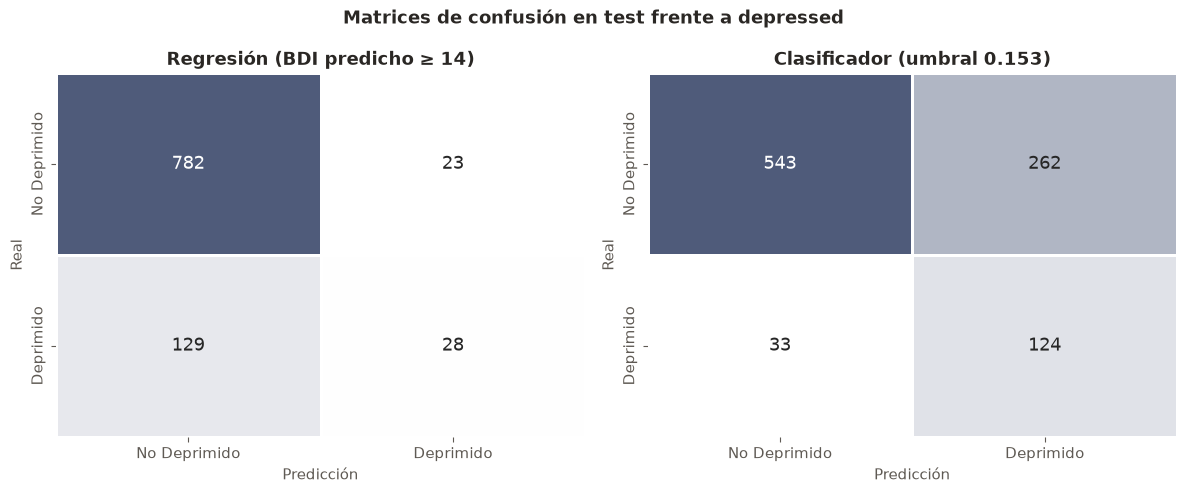

In [15]:
predicciones_clase = {f"Regresión (BDI predicho ≥ {CORTE_BDI})": (bdi_predicho >= CORTE_BDI).astype(int)}
if clasificador is not None:
    predicciones_clase[f"Clasificador (umbral {metadatos_clf['umbral']:.3f})"] = (proba_clf >= metadatos_clf["umbral"]).astype(int)
fig = graficar_matrices(y_dep_test, predicciones_clase, "Matrices de confusión en test frente a depressed")
plt.show()

Las matrices lo muestran: con el corte de 14, la regresión identifica a 28 de los 157 deprimidos y deja escapar a 129, con solo 23 falsas alarmas. El clasificador identifica a 124 y deja escapar a 33, a cambio de 262 falsas alarmas.

**¿Qué enfoque ordena mejor el riesgo?**

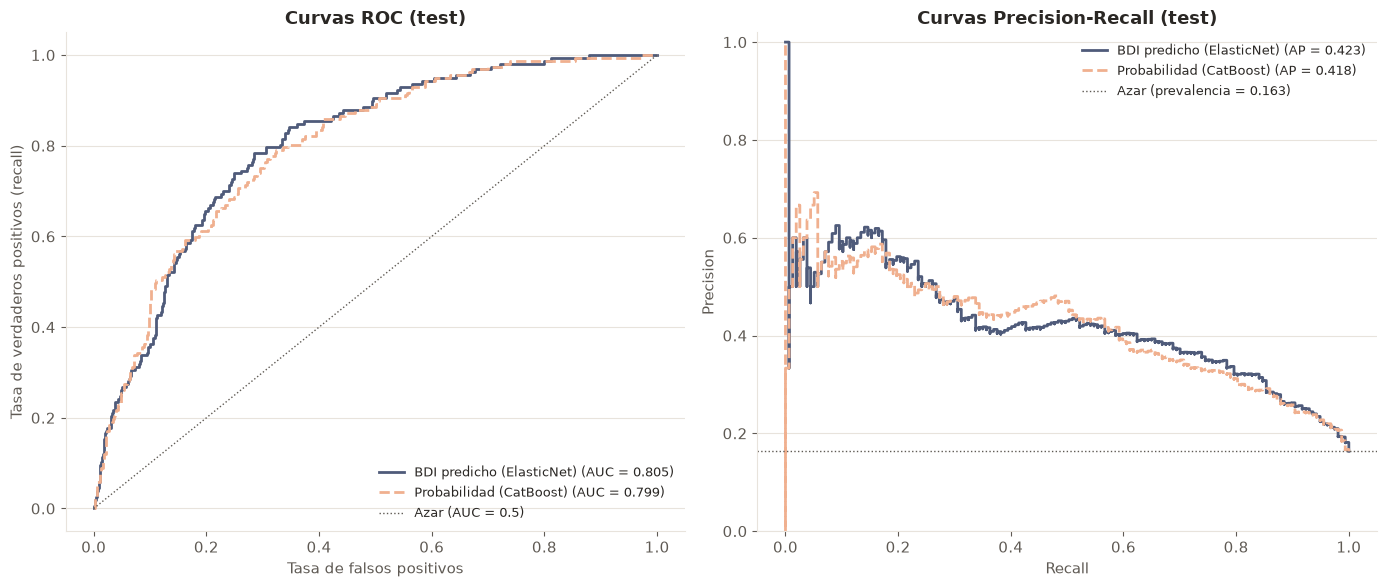

,PR-AUC,PR-AUC IC 2.5%,PR-AUC IC 97.5%,Δ PR-AUC vs clasificador,Δ PR-AUC IC 2.5%,Δ PR-AUC IC 97.5%,Δ PR-AUC significativa,ROC-AUC,ROC-AUC IC 2.5%,ROC-AUC IC 97.5%,Δ ROC-AUC vs clasificador,Δ ROC-AUC IC 2.5%,Δ ROC-AUC IC 97.5%,Δ ROC-AUC significativa
Modelo,,,,,,,,,,,,,,
Regresor (BDI predicho),0.423,0.352,0.513,0.006,-0.034,0.043,False,0.805,0.768,0.839,0.006,-0.005,0.018,False
Clasificador final,0.418,0.345,0.506,0.000,0.000,0.000,False,0.799,0.760,0.834,0.000,0.000,0.000,False


In [16]:
puntuaciones = {f"BDI predicho ({NOMBRES_REG[clave_mejor]})": bdi_predicho}
if clasificador is not None:
    puntuaciones[f"Probabilidad ({metadatos_clf['nombre']})"] = proba_clf
fig = graficar_roc_pr_riesgo(y_dep_test, puntuaciones)
plt.show()

if clasificador is not None:
    display(comparar_auc_bootstrap(y_dep_test, proba_clf, bdi_predicho, n_replicas=1000, seed=SEED).round(3))
else:
    print("⚠ No existe el clasificador final (data/processed/modelado/final/): no se puede comparar.")

Las curvas ROC y Precision-Recall de los dos enfoques están prácticamente superpuestas. Los intervalos bootstrap pareados confirman que la diferencia no es significativa: Δ PR-AUC = +0.006 (IC: −0.034 a 0.043) y Δ ROC-AUC = +0.006 (IC: −0.005 a 0.018), a favor del regresor pero con intervalos que incluyen el 0. Ambos enfoques ordenan el riesgo de forma equivalente. Para usar la regresión como herramienta de tamizaje, bastaría con elegir su propio umbral sobre el BDI predicho (con predicciones out-of-fold del train, como en la fase 3 de la clasificación), en lugar de aplicar el corte clínico de 14.

## Guardado del Modelo Final

Se guardan en `data/processed/modelado/regresion/final/` el modelo final (`modelo_final.joblib`, configurado para CPU), `metricas_test.csv` (la tabla de test de todos los modelos, con la columna `Modelo final`) y `metadatos.json`.

In [17]:
metricas_test = tabla_test.rename(index=NOMBRES_FASE2_REG)
metricas_test.insert(0, "Modelo final", tabla_test.index == clave_mejor)

metadatos = guardar_final_reg(pipelines[clave_mejor], clave_mejor, ganadores[clave_mejor], metricas_test, explicacion)

# Comprobación: el modelo guardado se carga y predice lo mismo
modelo_cargado, _ = cargar_modelo_regresion("final")
assert np.allclose(modelo_cargado.predict(X_test), bdi_predicho)
pd.Series({k: metadatos[k] for k in ["nombre", "variante_target", "usa_smearing", "dispositivo_entrenamiento"]}, name="Modelo final").to_frame()

,Modelo final
nombre,ElasticNet
variante_target,nativo
usa_smearing,False
dispositivo_entrenamiento,CPU


### Conclusiones

- Con los seis predictores, el BDI-II solo se predice de forma modesta. El mejor RMSE de CV es de unos 6.9 puntos (R² ≈ 0.20), y en el test, de 6.6 (R² = 0.23): los predictores reducen el error de predecir siempre la media en solo un 10–12%.
- Ningún modelo mejora significativamente a la regresión lineal benchmark. Los árboles (CatBoost, XGBoost y Random Forest) ganan por menos de 0.02 puntos en CV y pierden en el test, y los modelos de conteo y el SVR son peores. Por la regla de empate se elige ElasticNet, que en la práctica es la regresión lineal casi sin penalizar.
- En la fase 1, transformar el target (sqrt, log1p) o usar la pérdida Poisson no mejora el RMSE de forma relevante. Cuando se transforma, el smearing es imprescindible: sin él, las predicciones subestiman la media del BDI entre 1.5 y 2.7 puntos.
- La calidad del sueño y el sexo son, con diferencia, las variables más importantes, igual que en la clasificación. La duración del sueño y el tiempo de pantalla aportan poco, y el jetlag social, nada en el modelo lineal.
- Como herramienta de tamizaje, el corte clínico de 14 sobre el BDI predicho detecta solo el 18% de los deprimidos, porque las predicciones se comprimen hacia la media. Como puntuación de riesgo, en cambio, el BDI predicho ordena a los adolescentes igual de bien que el clasificador final (PR-AUC de 0.423 frente a 0.418 y ROC-AUC de 0.805 frente a 0.799; diferencias no significativas).